# 04a — GeometryStore as GeoPandas

Load GeometryStore tables into GeoDataFrames. `plot_dayhike` draws one DayHike
LineString from ordered vertices.

**Here:** `vertices` and `amenities` as points; `dayhikes` and `ways` as lines;
`plot_dayhike` for a one-row `dayhikes` slice; leftover members (`in_chain`,
`unconnected_m`).

**Not here:** Catalog SQLite (`02_catalog.ipynb`), production ranking
(`03_ranking.ipynb`), FeatureVector experiments (`04_rank_feature_lab.ipynb`).

Open `data/catalog.sqlite` plus `data/catalog.geometry.sqlite` when both exist.
Otherwise build the committed fixture. Ranking does not read this file.


In [ ]:
import json
import os
import sqlite3
import tempfile
from pathlib import Path

import geopandas as gpd
import pandas as pd
from shapely.geometry import LineString

from dayhike import build_catalog, geometry_store_path_for

repo = Path.cwd().resolve()
for candidate in (repo, *repo.parents):
    fixture = candidate / "tests" / "fixtures" / "catalog.osm"
    if fixture.is_file():
        repo = candidate
        break
else:
    raise FileNotFoundError("tests/fixtures/catalog.osm")

local = repo / "data" / "catalog.sqlite"
local_geometry = geometry_store_path_for(local)
if (
    local.is_file()
    and local_geometry.is_file()
    and "PYTEST_CURRENT_TEST" not in os.environ
):
    geometry_path = local_geometry
else:
    catalog_path = Path(tempfile.mkdtemp()) / "catalog.sqlite"
    build_catalog(fixture, catalog_path)
    geometry_path = geometry_store_path_for(catalog_path)

geo = sqlite3.connect(geometry_path)
print("geometry_store", geometry_path)
print("tables")
for (name,) in geo.execute(
    "SELECT name FROM sqlite_master WHERE type='table' ORDER BY 1"
):
    n = geo.execute(f'SELECT COUNT(*) FROM "{name}"').fetchone()[0]
    print(f"  {name}\t{n}")


## Load

`geometry_meta` has no coordinates (pandas only). The other four tables become
GeoDataFrames in EPSG:4326.

| Frame | Geometry |
| --- | --- |
| `vertices` | Point per OSM node on a DayHike |
| `amenities` | Point per raw amenity (including Viewpoint, Peak, Shelter) |
| `dayhikes` | LineString from ordered vertices |
| `ways` | LineString per member way |


In [ ]:
geometry_meta = pd.read_sql_query("SELECT * FROM geometry_meta", geo)
dayhikes_tbl = pd.read_sql_query("SELECT * FROM dayhikes", geo)
vertices_tbl = pd.read_sql_query(
    "SELECT * FROM vertices ORDER BY dayhike_id, seq", geo
)
ways_tbl = pd.read_sql_query("SELECT * FROM ways ORDER BY dayhike_id, seq", geo)
amenities_tbl = pd.read_sql_query("SELECT * FROM amenities", geo)

vertices = gpd.GeoDataFrame(
    vertices_tbl,
    geometry=gpd.points_from_xy(vertices_tbl.longitude, vertices_tbl.latitude),
    crs="EPSG:4326",
)
amenities = gpd.GeoDataFrame(
    amenities_tbl,
    geometry=gpd.points_from_xy(amenities_tbl.longitude, amenities_tbl.latitude),
    crs="EPSG:4326",
)

line_rows = []
for dayhike_id, grp in vertices_tbl.groupby("dayhike_id", sort=True):
    coords = list(zip(grp.longitude.to_numpy(), grp.latitude.to_numpy()))
    line_rows.append(
        {
            "id": int(dayhike_id),
            "geometry": LineString(coords) if len(coords) >= 2 else None,
        }
    )
dayhikes = gpd.GeoDataFrame(
    dayhikes_tbl.merge(pd.DataFrame(line_rows), on="id"),
    geometry="geometry",
    crs="EPSG:4326",
)

node_xy = (
    vertices_tbl.drop_duplicates("node_id").set_index("node_id")[
        ["longitude", "latitude"]
    ]
)


def way_line(node_ids_json: str) -> LineString | None:
    coords = []
    for node_id in json.loads(node_ids_json):
        if node_id not in node_xy.index:
            continue
        lon, lat = node_xy.loc[node_id]
        coords.append((float(lon), float(lat)))
    if len(coords) < 2:
        return None
    return LineString(coords)


ways = gpd.GeoDataFrame(
    ways_tbl,
    geometry=ways_tbl["node_ids"].map(way_line),
    crs="EPSG:4326",
)

geo.close()

for name, frame in (
    ("geometry_meta", geometry_meta),
    ("vertices", vertices),
    ("amenities", amenities),
    ("dayhikes", dayhikes),
    ("ways", ways),
):
    geom = getattr(frame, "geometry", None)
    extra = ""
    if geom is not None:
        extra = f"\tcrs={frame.crs}\tempty_geom={int(geom.isna().sum())}"
    print(f"geopandas {name}\t{frame.shape}{extra}")


The four spatial frames are in the kernel now: `vertices`, `amenities`,
`dayhikes`, `ways`. `geometry_meta` is attribution only.


In [ ]:
print("vertices")
print(vertices.head().to_string())
print("amenities kinds", amenities["kind"].value_counts().to_dict() if len(amenities) else {})
print("dayhikes")
hike_cols = [c for c in ("id", "name", "name_origin", "length_m", "unconnected_m") if c in dayhikes.columns]
print(dayhikes[hike_cols].to_string())
print("ways", len(ways), "member ways")
if "in_chain" in ways.columns:
    print("ways in_chain", ways["in_chain"].value_counts().to_dict())

if "PYTEST_CURRENT_TEST" in os.environ:
    import matplotlib as mpl

    mpl.use("Agg")
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 6))
if not dayhikes.empty:
    dayhikes.plot(ax=ax, color="#2a6", linewidth=2)
if not amenities.empty:
    amenities.plot(ax=ax, column="kind", markersize=20, legend=True)
ax.set_title("dayhikes + amenities")
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
fig.tight_layout()
try:
    from IPython.display import display

    display(fig)
except ImportError:
    pass
plt.close(fig)


In [ ]:
import math

from dayhike.catalog import EARTH_RADIUS_M

ends = (
    vertices.sort_values(["dayhike_id", "seq"])
    .groupby("dayhike_id")
    .agg(
        lat1=("latitude", "first"),
        lon1=("longitude", "first"),
        lat2=("latitude", "last"),
        lon2=("longitude", "last"),
    )
)


def haversine_m(lat1, lon1, lat2, lon2):
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2) ** 2
    return 2 * EARTH_RADIUS_M * math.asin(math.sqrt(a))


ends["start_end_m"] = [
    haversine_m(lat1, lon1, lat2, lon2)
    for lat1, lon1, lat2, lon2 in ends[["lat1", "lon1", "lat2", "lon2"]].itertuples(
        index=False
    )
]
dayhikes["start_end_m"] = dayhikes["id"].map(ends["start_end_m"])
print(dayhikes["start_end_m"].describe().to_string())
print("closed_lt_50m", int((dayhikes["start_end_m"] < 50).sum()))
dayhikes.sort_values("start_end_m")[["id", "name", "length_m", "start_end_m"]]

## Plot one DayHike

Pass a one-row `dayhikes` slice to `plot_dayhike`. The line is the assembled
vertex chain; red dots are those nodes; larger markers are the first and last
vertex.

`plot_dayhike_progress` keeps those start/end markers and colors the nodes in
between by position along the DayHike (start of colormap → end of colormap).

     id                       name     length_m
0  2381  Moorwanderweg Tanner Moor  5524.666368


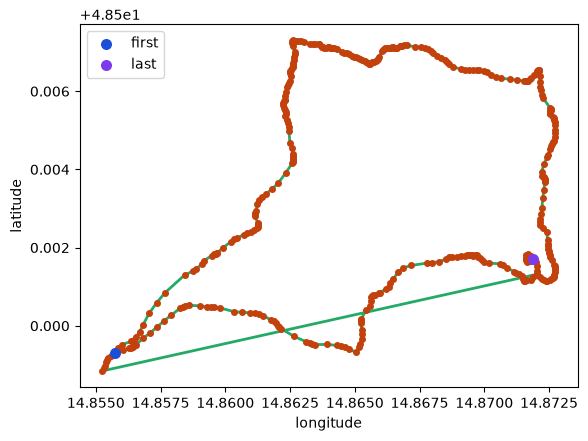

In [ ]:
def plot_dayhike(hike):
    fig, ax = plt.subplots(figsize=(6, 6))
    if hike.geometry.notna().any():
        hike.plot(ax=ax, color="#2a6", linewidth=2)
        for geom in hike.geometry.dropna():
            xs, ys = zip(*geom.coords)
            ax.scatter(xs, ys, s=16, color="#c2410c", zorder=3)
            ax.scatter(
                [xs[0]], [ys[0]], s=48, color="#1d4ed8", zorder=4, label="first"
            )
            ax.scatter(
                [xs[-1]], [ys[-1]], s=48, color="#7c3aed", zorder=5, label="last"
            )
        ax.legend()
    ax.set_xlabel("longitude")
    ax.set_ylabel("latitude")
    fig.tight_layout()
    try:
        from IPython.display import display

        display(fig)
    except ImportError:
        pass
    plt.close(fig)


one = dayhikes.iloc[[0]]
print(one[[c for c in ("id", "name", "length_m", "unconnected_m") if c in one.columns]].to_string())
plot_dayhike(one)

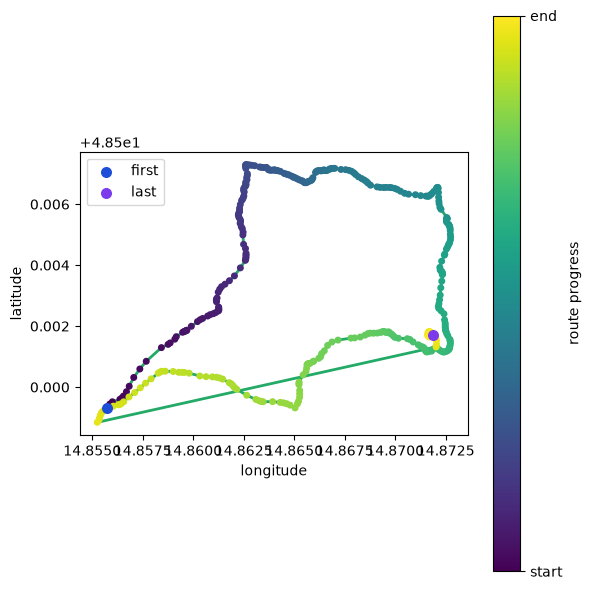

In [ ]:
def plot_dayhike_progress(hike):
    fig, ax = plt.subplots(figsize=(6, 6))
    if hike.geometry.notna().any():
        hike.plot(ax=ax, color="#2a6", linewidth=2)
        progress_shown = False
        for geom in hike.geometry.dropna():
            coords = list(geom.coords)
            n = len(coords)
            if n > 2:
                xs, ys = zip(*coords[1:-1])
                t = [i / (n - 1) for i in range(1, n - 1)]
                sc = ax.scatter(
                    xs,
                    ys,
                    c=t,
                    cmap="viridis",
                    vmin=0,
                    vmax=1,
                    s=16,
                    zorder=3,
                )
                if not progress_shown:
                    cbar = fig.colorbar(sc, ax=ax)
                    cbar.set_label("route progress")
                    cbar.set_ticks([0, 1])
                    cbar.set_ticklabels(["start", "end"])
                    progress_shown = True
            ax.scatter(
                [coords[0][0]], [coords[0][1]], s=48, color="#1d4ed8", zorder=5,
                label="first",
            )
            ax.scatter(
                [coords[-1][0]], [coords[-1][1]], s=48, color="#7c3aed", zorder=5,
                label="last",
            )
        ax.legend()
    ax.set_xlabel("longitude")
    ax.set_ylabel("latitude")
    fig.tight_layout()
    try:
        from IPython.display import display

        display(fig)
    except ImportError:
        pass
    plt.close(fig)


plot_dayhike_progress(one)

## Leftover member ways

OSM member order is not a guaranteed walk. Ingest glues a way only when it shares
an endpoint with the current chain; later members are still tried. Skipped ways
stay in `ways` with `in_chain = 0`. Their real length is `unconnected_m`.
Catalog `length_m` and the DayHike LineString follow the chain only — no jump
through empty space.

Prefer id 2381 when present (Moorwanderweg Tanner Moor: a short extra after a
near-loop). Otherwise the first DayHike with `unconnected_m > 0` (the fixture's
Ridge Walk). Leftover-way nodes that never appear on the chain are not in
`vertices`, so those extras may have empty geometry here. Interior attach and
dominant-cycle extract are later work (ADR-0009).

An older GeometryStore without these columns needs a re-ingest.

In [ ]:
if "unconnected_m" not in dayhikes.columns or "in_chain" not in ways.columns:
    print("leftover_ways\tskip_re_ingest")
else:
    leftover = dayhikes[dayhikes["unconnected_m"] > 0].copy()
    if 2381 in set(dayhikes["id"]):
        demo = dayhikes[dayhikes["id"] == 2381]
    elif not leftover.empty:
        demo = leftover.iloc[[0]]
    else:
        demo = dayhikes.iloc[[0]]
    demo_id = int(demo["id"].iloc[0])
    demo_ways = ways[ways["dayhike_id"] == demo_id]
    skipped = demo_ways[demo_ways["in_chain"] == 0]
    print(
        demo[
            [c for c in ("id", "name", "length_m", "unconnected_m") if c in demo.columns]
        ].to_string(index=False)
    )
    print("member ways")
    print(demo_ways[["seq", "way_id", "in_chain"]].to_string(index=False))
    print("skipped", len(skipped), "empty_geom", int(skipped.geometry.isna().sum()))

    fig, ax = plt.subplots(figsize=(6, 6))
    if demo.geometry.notna().any():
        demo.plot(ax=ax, color="#2a6", linewidth=2, label="chain")
    if not skipped.empty and skipped.geometry.notna().any():
        skipped.plot(ax=ax, color="#c2410c", linewidth=2, label="leftover")
    ax.legend()
    ax.set_title(f"leftover members · {demo['name'].iloc[0]}")
    ax.set_xlabel("longitude")
    ax.set_ylabel("latitude")
    fig.tight_layout()
    try:
        from IPython.display import display

        display(fig)
    except ImportError:
        pass
    plt.close(fig)